# 2025 — Gated Attention: a Sigmoid Gate after Attention

**Paper:** Zihan Qiu et al. (Qwen team), *"Gated Attention for Large Language Models: Non-linearity, Sparsity, and Attention-Sink-Free"* (arXiv 2505.06708, 2025; NeurIPS 2025 best paper). In production: the full-attention layers of **Qwen3-Next** and **Qwen3.5** (whose model card lists `15 × (3 × (Gated DeltaNet → MoE) → 1 × (Gated Attention → MoE))`).

A tiny change: multiply each head's attention output by a **sigmoid gate computed from the layer input**, before the output projection:

$$Y' = Y \odot \sigma(X W_\theta)$$

The paper tested about 30 variants on 15B MoE and 1.7B dense models. A head-specific, elementwise sigmoid gate right after scaled-dot-product attention (position "G1") worked best:
- **Lower perplexity:** 6.026 → 5.761 average on the 15B MoE
- **Stability:** at a high learning rate the 1.7B baseline diverged and the gated model trained fine
- **No attention sink:** baseline layers put on average 46.7% of their attention on the *first token* (a "sink" that soaks up attention when a head has nothing to do); with the gate this dropped to 4.8%. A gate can output ≈0, so a head no longer needs a dummy token to attend to.
- **Better long-context extrapolation** (RULER +10 points)

We compare a baseline and a gated small LM: validation loss at a normal and a high learning rate, and how much attention goes to the first token.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
# A procedurally generated corpus (~290K characters) with a real held-out split.
_rng = random.Random(0)
_subjects = ["the model", "a small network", "the optimizer", "each layer", "the attention head", "the router", "a student", "the teacher"]
_verbs = ["learns", "predicts", "updates", "compresses", "routes", "remembers", "forgets", "copies"]
_objects = ["the next token", "a hidden state", "the gradient", "its weights", "a long context", "the key and value", "every expert", "the loss"]
_advs = ["quickly", "slowly", "carefully", "in parallel", "step by step", "without labels", "at scale", "once again"]
def _sentence():
    s = f"{_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)} {_rng.choice(_advs)}"
    if _rng.random() < 0.4: s += f" because {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    if _rng.random() < 0.2: s += f", then {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    return s[0].upper() + s[1:] + ". "
text = "".join(_sentence() for _ in range(4000))
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
print(f"{len(text):,} characters, vocab {V}")

290,321 characters, vocab 31


In [3]:
class Attention(nn.Module):
    def __init__(self, d, heads, gated):
        super().__init__()
        self.h, self.dh, self.gated = heads, d // heads, gated
        self.qkv, self.o = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d, bias=False)
        if gated: self.gate = nn.Linear(d, d, bias=True)                                 # W_theta: elementwise, head-specific
        self.last_attn = None
    def forward(self, x, keep_attn=False):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, self.dh).permute(2, 0, 3, 1, 4)
        if keep_attn:                                                                    # explicit softmax, so we can inspect it
            a = (q @ k.transpose(-2, -1) / math.sqrt(self.dh)).masked_fill(torch.ones(T, T, dtype=torch.bool, device=x.device).triu(1), float("-inf")).softmax(-1)
            self.last_attn = a.detach(); y = a @ v
        else:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = y.transpose(1, 2).reshape(B, T, D)
        if self.gated: y = y * torch.sigmoid(self.gate(x))                                # the G1 gate
        return self.o(y)

class LM(nn.Module):
    def __init__(self, gated, d=128, n_layers=4, heads=4, ctx=128):
        super().__init__()
        self.ctx = ctx; self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(ctx, d)
        self.attn = nn.ModuleList([Attention(d, heads, gated) for _ in range(n_layers)])
        self.mlp = nn.ModuleList([nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d)) for _ in range(n_layers)])
        self.n1 = nn.ModuleList([nn.LayerNorm(d) for _ in range(n_layers)]); self.n2 = nn.ModuleList([nn.LayerNorm(d) for _ in range(n_layers)])
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, V, bias=False)
    def forward(self, idx, keep_attn=False):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1], device=idx.device))
        for a, m, n1, n2 in zip(self.attn, self.mlp, self.n1, self.n2):
            x = x + a(n1(x), keep_attn); x = x + m(n2(x))
        return self.head(self.ln(x))

def get_batch(src, B=32, ctx=128):
    ix = torch.randint(0, len(src) - ctx - 1, (B,), device=device)
    return src[ix[:, None] + torch.arange(ctx, device=src.device)], src[ix[:, None] + torch.arange(1, ctx + 1, device=src.device)]

def train(gated, lr, steps=600):
    seed_everything(0); m = LM(gated).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.1)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1); spikes = 0; prev = None
    for s in range(steps):
        x, y = get_batch(train_data); loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1))
        if prev is not None and loss.item() > 1.5 * prev and s > 50: spikes += 1
        prev = loss.item() if math.isfinite(loss.item()) else prev
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()                       # no gradient clipping: we want to see instability
    m.eval()
    with torch.no_grad():
        val = np.mean([F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)).item() for x, y in (get_batch(val_data) for _ in range(10))])
    return m, val, spikes

results = {}
for lr in [2e-3, 1e-2]:
    for gated in [False, True]:
        t0 = time.time(); results[(gated, lr)] = train(gated, lr)
        _, val, spikes = results[(gated, lr)]
        print(f"{'gated   ' if gated else 'baseline'} lr={lr:<6} val loss {val:.4f} | loss spikes {spikes:2d} | {time.time() - t0:.0f}s")

baseline lr=0.002  val loss 0.2200 | loss spikes  0 | 36s


gated    lr=0.002  val loss 0.2180 | loss spikes  0 | 36s


baseline lr=0.01   val loss 0.2129 | loss spikes  0 | 35s


gated    lr=0.01   val loss 0.2124 | loss spikes  0 | 38s


## Attention sinks: how much attention lands on the first token?
For each layer, average over heads and query positions (excluding the first few queries, which have few choices).

baseline: share of attention on token 0 per layer: [0.008 0.001 0.    0.001]
gated   : share of attention on token 0 per layer: [0.007 0.001 0.001 0.002]


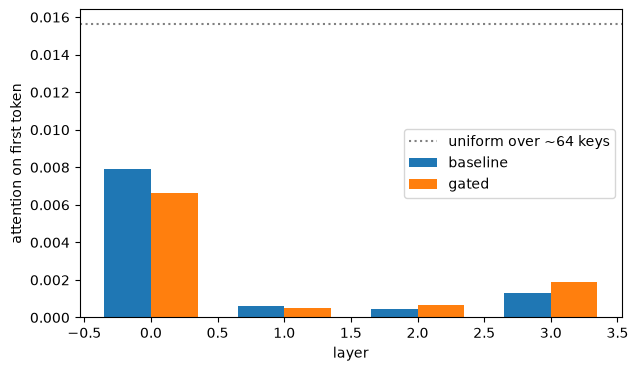

In [4]:
x, _ = get_batch(val_data, B=8)
fig, ax = plt.subplots(figsize=(7, 4)); width = 0.35
for k, gated in enumerate([False, True]):
    m = results[(gated, 2e-3)][0]
    with torch.no_grad(): m(x, keep_attn=True)
    sink = [a.last_attn[:, :, 16:, 0].mean().item() for a in m.attn]
    ax.bar(np.arange(len(sink)) + (k - 0.5) * width, sink, width, label="gated" if gated else "baseline")
    print(f"{'gated   ' if gated else 'baseline'}: share of attention on token 0 per layer: {np.round(sink, 3)}")
ax.axhline(1 / 64, ls=":", c="gray", label="uniform over ~64 keys"); ax.set_xlabel("layer"); ax.set_ylabel("attention on first token"); ax.legend(); plt.show()

## Takeaways
- The gate adds a cheap input-dependent non-linearity and lets a head switch itself off without dumping attention on a sink token.
- Whether the sink and stability effects show up depends on scale. The paper's sinks emerged in billion-parameter models trained on hundreds of billions of tokens, so treat the numbers above as a toy illustration, not a reproduction.
- Qwen3.5 combines this gated full attention (1 in 4 layers) with Gated DeltaNet (notebook 49) and MoE (notebook 44). The capstone notebook 58 builds exactly that stack.